# 06. Microcase: E-commerce Conversion Funnel

This is an independent microcase, using a separate e-commerce events
dataset, not connected to dunnhumby or PostgreSQL. It answers: at which
stage of the funnel (view → cart → purchase) do most sessions drop off, and
what is the true session-level conversion rate?

The unit of analysis is the session (`user_session`), not the user. A user
who views a product in one session and buys it in a later one counts as two
sessions, one without a purchase and one without a view, so every rate in
this notebook is a per-session rate. A per-user funnel could look different.

As with every dataset in this project, the file's actual structure is
inspected before any column names or types are assumed.

## 1. Raw File Inspection

Before any funnel logic, we confirm the file's real structure: columns, dtypes, row count, and a sample of rows.

In [1]:
import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"  # must be set before numpy/matplotlib load OpenMP

from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

RAW_DATA_DIR = Path("../data/raw/eCommerce Events History in Cosmetics Shop")

files = list(RAW_DATA_DIR.glob("*.csv"))
if not files:
    raise FileNotFoundError(f"No CSV files found under {RAW_DATA_DIR.resolve()}")
print(f"CSV files found: {[f.name for f in files]}")

for f in files:
    sample = pd.read_csv(f, nrows=5)
    with open(f) as fh:
        n_rows = sum(1 for _ in fh) - 1
    print(f"\n--- {f.name} ---")
    print(f"Rows: {n_rows}")
    print(f"Columns: {list(sample.columns)}")
    print(sample.head())

filepath = files[0]

CSV files found: ['2019-Nov.csv']

--- 2019-Nov.csv ---
Rows: 4635837
Columns: ['event_time', 'event_type', 'product_id', 'category_id', 'category_code', 'brand', 'price', 'user_id', 'user_session']
                event_time        event_type  product_id          category_id  \
0  2019-11-01 00:00:02 UTC              view     5802432  1487580009286598681   
1  2019-11-01 00:00:09 UTC              cart     5844397  1487580006317032337   
2  2019-11-01 00:00:10 UTC              view     5837166  1783999064103190764   
3  2019-11-01 00:00:11 UTC              cart     5876812  1487580010100293687   
4  2019-11-01 00:00:24 UTC  remove_from_cart     5826182  1487580007483048900   

   category_code     brand  price    user_id  \
0            NaN       NaN   0.32  562076640   
1            NaN       NaN   2.38  553329724   
2            NaN       pnb  22.22  556138645   
3            NaN  jessnail   3.16  564506666   
4            NaN       NaN   3.33  553329724   

                         

Only one file is present (`2019-Nov.csv`, 4,635,837 rows), covering
November 2019. `category_code` and `brand` show nulls even in the
5-row sample (expected for a real e-commerce catalog, not every product
is categorized or branded), and `event_time` is a proper UTC timestamp
string, not a sequential integer like dunnhumby's `DAY`.

More importantly, `event_type` includes a 4th value beyond the three
funnel stages: `remove_from_cart`, alongside `view`
and `cart` (row 4). This doesn't change the funnel stages themselves (view
→ cart → purchase), but it means a `cart` event should still count toward
reaching the cart stage even if the item is later removed, the removal is
a separate downstream action, not a retroactive cancellation of having
reached that stage. This needs verifying against the full distinct value
count, not assumed from a 5-row sample.

### 1.1 Confirming event_type values and date range

Before building the funnel, we confirm all distinct `event_type` values
(not just what a 5-row sample showed) and the actual date range covered.

In [2]:
event_types = pd.read_csv(filepath, usecols=["event_type"])
print("event_type value counts:")
print(event_types["event_type"].value_counts())

date_range = pd.read_csv(filepath, usecols=["event_time"])
date_range["event_time"] = pd.to_datetime(date_range["event_time"])
print(f"\nDate range: {date_range['event_time'].min()} to {date_range['event_time'].max()}")

event_type value counts:
event_type
view                2076132
cart                1311807
remove_from_cart     925481
purchase             322417
Name: count, dtype: int64

Date range: 2019-11-01 00:00:02+00:00 to 2019-11-30 23:59:58+00:00


Exactly 4 distinct `event_type` values confirmed, no hidden categories
beyond the 5-row sample. `remove_from_cart` (925,481 events) sits between
`cart` and `purchase` in volume, consistent with it being a legitimate
downstream action rather than a data artifact. The date range confirms
full, clean coverage of November 2019 (Nov 1 00:00 to Nov 30 23:59), no
partial or overlapping months to worry about.

The raw event counts already hint at the funnel shape: 2,076,132 views,
1,311,807 carts, 322,417 purchases, a clear narrowing at each stage, to be
quantified precisely in the next section.

## 2. Building the Funnel by Session

For each `user_session`, we determine whether it reached each funnel stage
at least once: view, cart, and purchase. A session "reaches" a stage if it
contains at least one event of that type, regardless of how many times or
in what exact order, session-level funnels conventionally measure reach,
not strict sequential order, since real browsing behavior isn't always
linear (a user might view, cart, view more, then purchase). Before grouping, we check `user_session` itself for nulls and drop any row that has one: a missing session ID can't be attributed to any session, so it can only be excluded, not silently folded into a group. Stage membership is then read directly off boolean filters instead of building a per-session set of event types first: grouping 4.6M rows into ~942K Python `set` objects only to ask "does this set contain 'view'" for each one is far slower than filtering the event column once per stage and keeping the session IDs that match.

In [3]:
usecols = ["event_type", "user_session"]
events_raw = pd.read_csv(filepath, usecols=usecols)

n_null_sessions = events_raw["user_session"].isna().sum()
pct_null_sessions = n_null_sessions / len(events_raw) * 100
print(f"Rows with a missing user_session: {n_null_sessions:,} ({pct_null_sessions:.3f}% of {len(events_raw):,} events)")

events = events_raw.dropna(subset=["user_session"])
print(f"Rows retained for the session-level funnel: {len(events):,}")

all_sessions = set(events["user_session"])
sessions_with_view = set(events.loc[events["event_type"] == "view", "user_session"])
sessions_with_cart = set(events.loc[events["event_type"] == "cart", "user_session"])
sessions_with_purchase = set(events.loc[events["event_type"] == "purchase", "user_session"])

n_total_sessions = len(all_sessions)
n_view = len(sessions_with_view)
n_cart = len(sessions_with_cart)
n_purchase = len(sessions_with_purchase)

funnel = pd.DataFrame({
    "stage": ["View", "Cart", "Purchase"],
    "n_sessions": [n_view, n_cart, n_purchase],
})
funnel["pct_of_total"] = (funnel["n_sessions"] / n_total_sessions * 100).round(2)
funnel["pct_of_previous"] = (funnel["n_sessions"] / funnel["n_sessions"].shift(1) * 100).round(2)

print(f"Total sessions: {n_total_sessions}")
funnel

Rows with a missing user_session: 813 (0.018% of 4,635,837 events)
Rows retained for the session-level funnel: 4,635,024
Total sessions: 942022


,stage,n_sessions,pct_of_total,pct_of_previous
0,View,883543,93.79,NaN
1,Cart,212862,22.60,24.09
2,Purchase,36568,3.88,17.18


Of 942,022 total sessions, 93.79% include at least one view, but only 22.6%
reach the cart stage, and just 3.88% result in a purchase. The `NaN` for View's `pct_of_previous` is expected, there's no stage before
View to calculate a conversion rate from.

Two different questions give two different answers about "where the funnel
is worst." By raw percentage-point drop, View → Cart loses the most ground
(93.79% → 22.6%, a 71-point fall). But by stage-to-stage conversion *rate*,
Cart → Purchase is actually the weaker stage: only 17.18% of sessions that
reach cart go on to purchase, compared to 24.09% of sessions that reach view
also reaching cart. In other words, users are somewhat more likely to
abandon after adding to cart than they are to never cart something they've
viewed, a genuine cart-abandonment problem, not just a top-of-funnel
awareness issue.

### 2.1 Verifying stage-to-stage rates against true session overlap

`pct_of_previous` in the funnel table above is a ratio between independent stage totals (`n_sessions[stage] / n_sessions[stage-1]`), not a session-level conditional rate. These are only equivalent if every purchasing session also has a cart event, and every carting session also has a view event, an assumption that needs checking, not assuming, especially since "buy now" flows that skip the cart are common in real e-commerce.

In [4]:
purchase_without_cart = sessions_with_purchase - sessions_with_cart
cart_without_view = sessions_with_cart - sessions_with_view

print(f"Purchases without a cart event: {len(purchase_without_cart):,} "
      f"({len(purchase_without_cart) / len(sessions_with_purchase):.1%} of all purchases)")
print(f"Carts without a view event: {len(cart_without_view):,} "
      f"({len(cart_without_view) / len(sessions_with_cart):.1%} of all carts)")

true_cart_to_purchase = len(sessions_with_cart & sessions_with_purchase) / len(sessions_with_cart) * 100
true_view_to_cart = len(sessions_with_view & sessions_with_cart) / len(sessions_with_view) * 100

print(f"\nTrue Cart → Purchase conditional rate: {true_cart_to_purchase:.2f}%")
print(f"True View → Cart conditional rate: {true_view_to_cart:.2f}%")

Purchases without a cart event: 7,060 (19.3% of all purchases)
Carts without a view event: 44,824 (21.1% of all carts)

True Cart → Purchase conditional rate: 13.86%
True View → Cart conditional rate: 19.02%


The two conditional rates above describe stage-to-stage transitions, but they don't show the actual *paths* purchasing sessions took to get there. We break the 36,568 purchase sessions down by which earlier stages they actually passed through, using the same three sets, no new data read required.

In [5]:
purchase_with_view = sessions_with_purchase & sessions_with_view
purchase_with_cart = sessions_with_purchase & sessions_with_cart

purchase_paths = pd.DataFrame([
    {"path": "View + Cart + Purchase", "n_sessions": len(purchase_with_view & purchase_with_cart)},
    {"path": "Cart + Purchase (no View)", "n_sessions": len(purchase_with_cart - purchase_with_view)},
    {"path": "View + Purchase (no Cart)", "n_sessions": len(purchase_with_view - purchase_with_cart)},
    {"path": "Purchase only (no View, no Cart)",
     "n_sessions": len(sessions_with_purchase - purchase_with_view - purchase_with_cart)},
])
purchase_paths["pct_of_purchases"] = (purchase_paths["n_sessions"] / len(sessions_with_purchase) * 100).round(1)

assert purchase_paths["n_sessions"].sum() == len(sessions_with_purchase)
purchase_paths

,path,n_sessions,pct_of_purchases
0,View + Cart + Purchase,25031,68.5
1,Cart + Purchase (no View),4477,12.2
2,View + Purchase (no Cart),2401,6.6
3,"Purchase only (no View, no Cart)",4659,12.7


This decomposes the 7,060 purchase sessions without a cart event (19.3% of purchases) into where those sessions actually came from. About a third (2,401, 6.6% of purchases) went straight from a view to a purchase ("buy now"-style). The other two thirds (4,659, 12.7% of purchases) have no recorded view *or* cart at all, purchase is the only logged event of the session. The data doesn't say why. Possible explanations include sessions that began before November 1, earlier activity logged under a different `user_session` id, or purchase flows that don't emit view or cart events; this notebook can't tell them apart.

## 3. Funnel Visualization

The session-level counts provide a useful overview of how many sessions reached each stage, but they should not be interpreted as a strictly sequential funnel because some sessions reached `cart` without a `view`, and some reached `purchase` without a recorded `cart` event.

The visualization therefore shows **stage reach** rather than assuming that every session must pass through the previous stage.

The conditional conversion rates calculated from actual session overlap are:

* **View → Cart:** 19.02%
* **Cart → Purchase:** 13.86%
* **Overall Purchase Reach:** 3.88%

This distinction is important for interpreting the funnel correctly: the stage totals describe how many sessions reached each event, while the conditional rates describe how often sessions that reached one stage also reached the next stage.

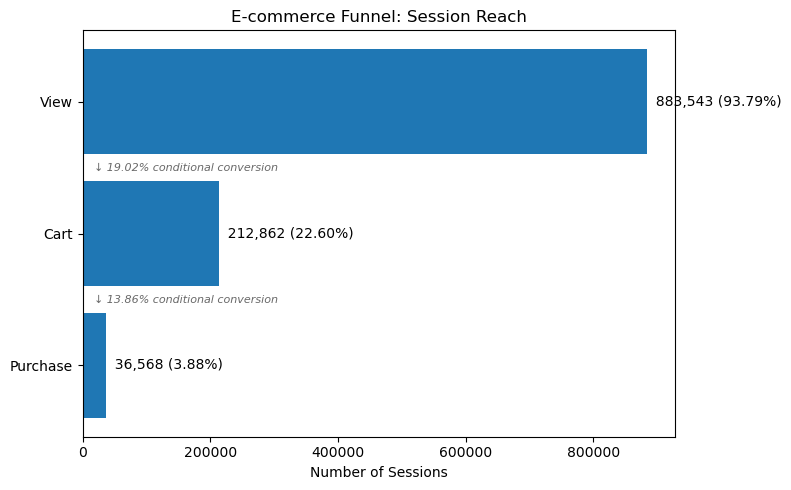

In [6]:
stages = funnel["stage"]
counts = funnel["n_sessions"]
pct_total = funnel["pct_of_total"]

fig, ax = plt.subplots(figsize=(8, 5))

ax.barh(stages, counts)

for i, (stage, n, pct) in enumerate(zip(stages, counts, pct_total)):
    ax.text(n, i, f"  {n:,} ({pct:.2f}%)", va="center")

conditional_rates = [true_view_to_cart, true_cart_to_purchase]
annotation_x = counts.max() * 0.02
for i, rate in enumerate(conditional_rates):
    ax.text(annotation_x, i + 0.5, f"↓ {rate:.2f}% conditional conversion",
            va="center", ha="left", fontsize=8, color="dimgray", style="italic")

ax.invert_yaxis()

ax.set_xlabel("Number of Sessions")
ax.set_title("E-commerce Funnel: Session Reach")
plt.tight_layout()

from pathlib import Path as _Path
_Path("../outputs/figures").mkdir(parents=True, exist_ok=True)
plt.savefig('../outputs/figures/06_funnel_conversion.png', bbox_inches='tight', dpi=300)
plt.show()

The chart makes the drop-off shape immediately clear: `View` and `Cart` are on comparable visual scales, but `Purchase` barely registers next to them. This is the same story the conditional rates already told numerically, the steepest proportional loss happens between `Cart` and `Purchase` (13.86%), while the biggest absolute loss happens between `View` and `Cart`, simply because so many more sessions start there.

## 4. Conclusion

This microcase set out to answer two questions: where does the largest funnel drop-off occur, and what is the actual session-level conversion rate?

Using 942,022 sessions from November 2019, the analysis found that:

* **883,543 sessions (93.79%)** included at least one product view.
* **212,862 sessions (22.60%)** reached the cart stage.
* **36,568 sessions (3.88%)** included a purchase.

The analysis also showed why simple ratios between stage totals can be misleading. Not every cart session contained a recorded view, and not every purchase session contained a recorded cart event; the path breakdown in Section 2.1 shows that of the 7,060 purchase sessions without a cart event, about a third (2,401) had a view and the other two thirds (4,659) had neither a view nor a cart. Therefore, the true conditional rates based on session overlap are:

* **View → Cart: 19.02%**
* **Cart → Purchase: 13.86%**

This makes **Cart → Purchase the weaker transition in proportional terms**. Once a session reaches the cart, only 13.86% of those sessions also contain a purchase event.

At the same time, **View → Cart represents the largest absolute loss of potential customers**, because the number of sessions reaching the cart is substantially smaller than the number reaching the view stage.

From a business perspective, the two findings suggest different opportunities:

1. **Cart → Purchase:** the lowest conditional conversion rate makes this the most direct candidate for investigation. Checkout friction, pricing, delivery costs, payment issues, or lack of purchase confidence could potentially contribute to this drop-off.
2. **View → Cart:** the much larger absolute loss suggests a broader opportunity to improve product-page engagement, product relevance, merchandising, or add-to-cart behavior.

All of these rates are per session. Users can browse in one session and buy in another, so per-user conversion could differ substantially from the 3.88% session rate; this notebook doesn't measure it.

The overall purchase reach of **3.88%** provides a baseline for future experiments. Any intervention designed to improve e-commerce conversion should be evaluated against this baseline using a controlled comparison whenever possible.

A final methodological point is important: this dataset records events at the session level, so the analysis measures **event reach within sessions**, not necessarily the exact chronological sequence of user actions. The results should therefore be interpreted as a session-level behavioral funnel rather than a perfectly sequential customer journey.